In [3]:
import json
from pathlib import Path

data_path = Path("../data/raw/18244_events.json")

with data_path.open("r", encoding="utf-8") as file:
    events = json.load(file)

print(f"Total events: {len(events)}")
print(f"Python type: {type(events)}")
print(f"First event type: {type(events[0])}")

Total events: 3400
Python type: <class 'list'>
First event type: <class 'dict'>


In [4]:
first_event = events[0]

print("Fields in the first event:")
print(list(first_event.keys()))

Fields in the first event:
['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type', 'possession', 'possession_team', 'play_pattern', 'team', 'duration', 'tactics']


In [5]:
shot = next(
    event for event in events
    if event["type"]["name"] == "Shot"
)

pass_event = next(
    event for event in events
    if event["type"]["name"] == "Pass"
)

print("Shot fields:")
print(list(shot.keys()))

print("\nPass fields:")
print(list(pass_event.keys()))

Shot fields:
['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type', 'possession', 'possession_team', 'play_pattern', 'team', 'player', 'position', 'location', 'duration', 'related_events', 'shot']

Pass fields:
['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type', 'possession', 'possession_team', 'play_pattern', 'team', 'player', 'position', 'location', 'duration', 'related_events', 'pass']


In [6]:
print("SHOT")
print(json.dumps(shot, indent=2, ensure_ascii=False))

print("\nPASS")
print(json.dumps(pass_event, indent=2, ensure_ascii=False))

SHOT
{
  "id": "edbeec9b-c1a4-46dd-9b99-1df1d9a8e6fa",
  "index": 155,
  "period": 1,
  "timestamp": "00:02:50.064",
  "minute": 2,
  "second": 50,
  "type": {
    "id": 16,
    "name": "Shot"
  },
  "possession": 9,
  "possession_team": {
    "id": 224,
    "name": "Juventus"
  },
  "play_pattern": {
    "id": 4,
    "name": "From Throw In"
  },
  "team": {
    "id": 224,
    "name": "Juventus"
  },
  "player": {
    "id": 5497,
    "name": "Gonzalo Gerardo Higuaín"
  },
  "position": {
    "id": 23,
    "name": "Center Forward"
  },
  "location": [
    106.0,
    37.0
  ],
  "duration": 0.938222,
  "related_events": [
    "ee33d2ca-e1a3-4556-bf8d-8887661101e0"
  ],
  "shot": {
    "statsbomb_xg": 0.07028022,
    "end_location": [
      120.0,
      41.9,
      1.1
    ],
    "key_pass_id": "1caf54ad-0da7-44d3-854d-e89616dffe1c",
    "type": {
      "id": 87,
      "name": "Open Play"
    },
    "outcome": {
      "id": 100,
      "name": "Saved"
    },
    "technique": {
      "id": 

In [7]:
shot_details = shot["shot"]

print("Shot details:")
for key, value in shot_details.items():
    print(f"{key}: {value}")

print("\nShot location:", shot.get("location"))
print("Player:", shot.get("player", {}).get("name"))
print("Team:", shot.get("team", {}).get("name"))

Shot details:
statsbomb_xg: 0.07028022
end_location: [120.0, 41.9, 1.1]
key_pass_id: 1caf54ad-0da7-44d3-854d-e89616dffe1c
type: {'id': 87, 'name': 'Open Play'}
outcome: {'id': 100, 'name': 'Saved'}
technique: {'id': 93, 'name': 'Normal'}
body_part: {'id': 37, 'name': 'Head'}
freeze_frame: [{'location': [120.0, 41.0], 'player': {'id': 5597, 'name': 'Keylor Navas Gamboa'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'teammate': False}, {'location': [108.0, 41.0], 'player': {'id': 5201, 'name': 'Sergio Ramos García'}, 'position': {'id': 5, 'name': 'Left Center Back'}, 'teammate': False}, {'location': [108.0, 37.0], 'player': {'id': 5485, 'name': 'Raphaël Varane'}, 'position': {'id': 3, 'name': 'Right Center Back'}, 'teammate': False}, {'location': [104.0, 35.0], 'player': {'id': 5574, 'name': 'Toni Kroos'}, 'position': {'id': 13, 'name': 'Right Center Midfield'}, 'teammate': False}, {'location': [109.0, 32.0], 'player': {'id': 6945, 'name': 'Alex Sandro Lobo Silva'}, 'position': {'id': 6

In [11]:
shots_data = []

for event in events:
    if event["type"]["name"] == "Shot":
        shot_info = {
            "event_id": event["id"],
            "team_name": event["team"]["name"],
            "player_name": event["player"]["name"],
            "minute": event.get("minute"),
            "location": event.get("location"),
            "outcome": event.get("shot", {}).get("outcome", {}).get("name"),
            "xG": event.get("shot", {}).get("statsbomb_xg"),
        }
        shots_data.append(shot_info)



In [13]:
import pandas as pd

shots_df = pd.DataFrame(shots_data)


# First five rows
shots_df.head()

# Number of rows and columns
shots_df.shape

# Column names and data types
shots_df.info()

# Summary of missing values
shots_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   event_id     27 non-null     str    
 1   team_name    27 non-null     str    
 2   player_name  27 non-null     str    
 3   minute       27 non-null     int64  
 4   location     27 non-null     object 
 5   outcome      27 non-null     str    
 6   xG           27 non-null     float64
dtypes: float64(1), int64(1), object(1), str(4)
memory usage: 1.6+ KB


event_id       0
team_name      0
player_name    0
minute         0
location       0
outcome        0
xG             0
dtype: int64

In [18]:
juventus_shots = shots_df[
    shots_df["team_name"] == "Juventus"
]

real_madrid_shots = shots_df[
    shots_df["team_name"] == "Real Madrid"
]



In [19]:
goals = shots_df[
    shots_df["outcome"] == "Goal"
]

goals

,event_id,team_name,player_name,minute,location,outcome,xG
3,af7c575a-50d8-419a-89a5-b4abbc11e3c9,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,19,"[105.0, 44.0]",Goal,0.085427
6,2fed9dfd-c530-4567-b3e3-915490a97b84,Juventus,Mario Mandžukić,26,"[106.0, 30.0]",Goal,0.037088
17,b1386445-4202-40c7-ab28-53507c68d2e9,Real Madrid,Carlos Henrique Casimiro,60,"[90.0, 34.0]",Goal,0.017447
18,944e9b65-7263-45e7-9cea-00379048a157,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,63,"[117.0, 47.0]",Goal,0.136510
24,b5dd76c7-aa5d-4e7c-9686-e701b8310790,Real Madrid,Marco Asensio Willemsen,89,"[113.0, 40.0]",Goal,0.401261


In [23]:
juventus_goals = shots_df[
    (shots_df["team_name"] == "Juventus") &
    (shots_df["outcome"] == "Goal")
]

real_madrid_goals = shots_df[
    (shots_df["team_name"] == "Real Madrid") &
    (shots_df["outcome"] == "Goal")
]


In [25]:
high_quality_shots = shots_df[
    shots_df["xG"] >= 0.20
]

high_quality_shots

,event_id,team_name,player_name,minute,location,outcome,xG
19,40d1bad9-beae-405c-b42e-c9cd0c306529,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,72,"[111.0, 42.0]",Off T,0.281407
24,b5dd76c7-aa5d-4e7c-9686-e701b8310790,Real Madrid,Marco Asensio Willemsen,89,"[113.0, 40.0]",Goal,0.401261


In [27]:
team_summary = shots_df.groupby("team_name").agg(
    total_shots=("team_name", "size"),
    goals=("outcome", lambda s: (s == "Goal").sum()),
    average_xg=("xG", "mean"),
    total_xg=("xG", "sum")
)

team_summary

,total_shots,goals,average_xg,total_xg
team_name,,,,
Juventus,9,1,0.046575,0.419174
Real Madrid,18,4,0.087318,1.571722


In [29]:
shots_df["team_name"].value_counts()



team_name
Real Madrid    18
Juventus        9
Name: count, dtype: int64

In [30]:
shots_df.groupby(
    ["team_name", "outcome"]
).size().unstack(fill_value=0)

outcome,Blocked,Goal,Off T,Saved,Wayward
team_name,,,,,
Juventus,4,1,1,3,0
Real Madrid,7,4,5,1,1


In [31]:
shots_df.groupby("team_name")["xG"].agg(
    ["count", "sum", "mean", "max"]
).round(3)

,count,sum,mean,max
team_name,,,,
Juventus,9,0.419,0.047,0.071
Real Madrid,18,1.572,0.087,0.401


In [32]:
print(shots_df[["team_name", "player_name", "location", "xG", "outcome"]].head(10))

     team_name                          player_name       location        xG  \
0     Juventus              Gonzalo Gerardo Higuaín  [106.0, 37.0]  0.070280   
1     Juventus              Gonzalo Gerardo Higuaín   [92.0, 49.0]  0.023390   
2     Juventus                       Miralem Pjanić   [98.0, 35.0]  0.044918   
3  Real Madrid  Cristiano Ronaldo dos Santos Aveiro  [105.0, 44.0]  0.085427   
4     Juventus                       Miralem Pjanić  [105.0, 51.0]  0.053712   
5     Juventus              Gonzalo Gerardo Higuaín  [100.0, 39.0]  0.052340   
6     Juventus                      Mario Mandžukić  [106.0, 30.0]  0.037088   
7  Real Madrid  Cristiano Ronaldo dos Santos Aveiro  [105.0, 42.0]  0.047854   
8  Real Madrid  Cristiano Ronaldo dos Santos Aveiro  [112.0, 45.0]  0.176242   
9     Juventus          Paulo Bruno Exequiel Dybala   [89.0, 50.0]  0.025291   

   outcome  
0    Saved  
1    Saved  
2    Saved  
3     Goal  
4  Blocked  
5  Blocked  
6     Goal  
7  Blocked  
8 

In [33]:
shots_df["location"].apply(
    lambda loc: isinstance(loc, list) and len(loc) == 2
).value_counts()

location
True    27
Name: count, dtype: int64

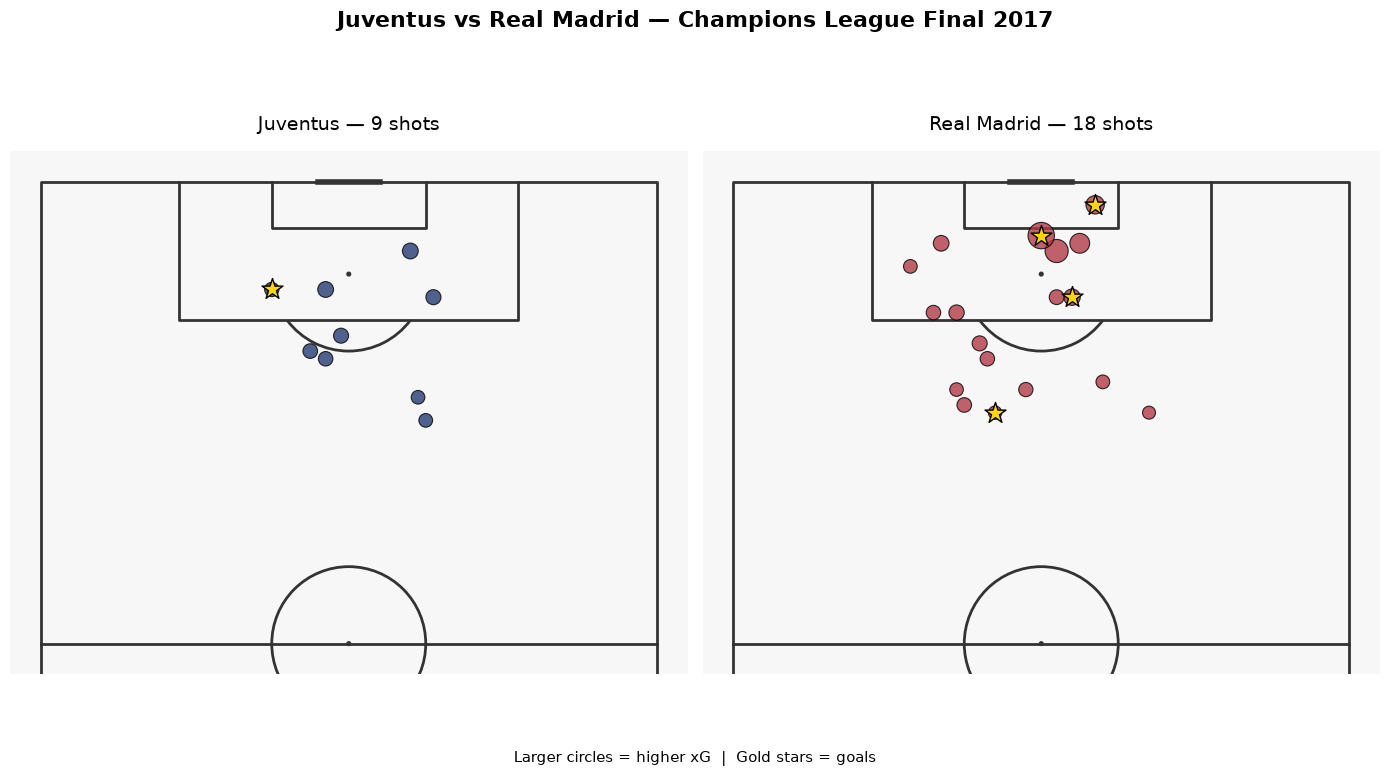

In [35]:
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

# Create the two shot maps
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

pitch = VerticalPitch(
    pitch_type="statsbomb",
    half=True,
    pitch_color="#f7f7f7",
    line_color="#333333"
)

teams = [
    ("Juventus", "#263b73"),
    ("Real Madrid", "#b23a48")
]

for ax, (team, color) in zip(axes, teams):

    # Select shots for the current team
    team_shots = shots_df[shots_df["team_name"] == team].copy()

    # Extract the x and y coordinates
    x = team_shots["location"].str[0]
    y = team_shots["location"].str[1]

    # Scale marker size according to expected goals
    marker_sizes = 80 + team_shots["xG"] * 700

    # Draw the pitch
    pitch.draw(ax=ax)

    # Plot all shots
    pitch.scatter(
        x, y,
        s=marker_sizes,
        c=color,
        edgecolors="black",
        linewidth=0.8,
        alpha=0.8,
        ax=ax,
        zorder=2
    )

    # Highlight goals with gold stars
    goals = team_shots[team_shots["outcome"] == "Goal"]

    if not goals.empty:
        pitch.scatter(
            goals["location"].str[0],
            goals["location"].str[1],
            marker="*",
            s=250,
            c="gold",
            edgecolors="black",
            linewidth=1,
            ax=ax,
            zorder=3
        )

    ax.set_title(f"{team} — {len(team_shots)} shots", fontsize=14, pad=15)

fig.suptitle(
    "Juventus vs Real Madrid — Champions League Final 2017",
    fontsize=16,
    fontweight="bold"
)

plt.figtext(
    0.5, 0.04,
    "Larger circles = higher xG  |  Gold stars = goals",
    ha="center",
    fontsize=11
)

plt.tight_layout(rect=[0, 0.07, 1, 0.93])
plt.show()

In [38]:
# Rank every shot by its expected-goal value
top_shots = shots_df.sort_values(
    by="xG",
    ascending=False
)

top_shots[
    ["team_name", "player_name", "minute", "xG", "outcome"]
].head(10)

,team_name,player_name,minute,xG,outcome
24,Real Madrid,Marco Asensio Willemsen,89,0.401261,Goal
19,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,72,0.281407,Off T
8,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,32,0.176242,Wayward
18,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,63,0.136510,Goal
3,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,19,0.085427,Goal
22,Juventus,Alex Sandro Lobo Silva,81,0.070652,Off T
0,Juventus,Gonzalo Gerardo Higuaín,2,0.070280,Saved
20,Real Madrid,Karim Benzema,74,0.067564,Blocked
16,Real Madrid,Toni Kroos,60,0.059819,Blocked
4,Juventus,Miralem Pjanić,22,0.053712,Blocked


In [39]:
team_shot_quality = (
    shots_df.groupby("team_name")
    .agg(
        shots=("xG", "count"),
        goals=("outcome", lambda s: (s == "Goal").sum()),
        total_xG=("xG", "sum"),
        average_xG=("xG", "mean"),
        highest_xG=("xG", "max")
    )
    .reset_index()
)

team_shot_quality["goals_minus_xG"] = (
    team_shot_quality["goals"] - team_shot_quality["total_xG"]
)

team_shot_quality.round(3)

,team_name,shots,goals,total_xG,average_xG,highest_xG,goals_minus_xG
0,Juventus,9,1,0.419,0.047,0.071,0.581
1,Real Madrid,18,4,1.572,0.087,0.401,2.428
